# GI Lab: Weisfeiler–Leman experiments

This notebook is a hands-on entry point for the graph-isomorphism workbench. It uses only the project source and Python's standard library; Jupyter is supplied by the accompanying Conda environment.

From the repository root, create and launch the environment:

```bash
conda env create -f environment.yml
conda activate gi-lab
jupyter lab
```

In [1]:
# Make the repository source importable when Jupyter starts in notebooks/.
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from gi_lab.algorithms import ColorRefinement, StationaryDistribution, TwoWL
from gi_lab.exact import is_isomorphic
from gi_lab.families import (
    cycle, disjoint_cycles, rook_graph, shrikhande_graph,
    default_corpus,
)
from gi_lab.experiments import run
from gi_lab.graph import Graph
from gi_lab.search import find_collision
from gi_lab.draw import draw_pair


## Build graphs by hand

`Graph.from_edges` is the most direct way to encode a small example. Isolated vertices can be supplied explicitly.

In [2]:
triangle_plus_isolate = Graph.from_edges(
    [(0, 1), (1, 2), (2, 0)],
    vertices=range(4),
)
triangle_plus_isolate.describe(), triangle_plus_isolate.edge_list()

({'vertices': 4, 'edges': 3, 'min_degree': 0, 'max_degree': 2},
 [(0, 1), (0, 2), (1, 2)])

## Compare a known 1-WL failure

The 12-cycle and two disjoint 6-cycles are not isomorphic, but every vertex has degree two. Therefore 1-WL reaches the same single-colour partition. 2-WL distinguishes them.

1wl: same signature = True
2wl: same signature = False
exactly isomorphic: False


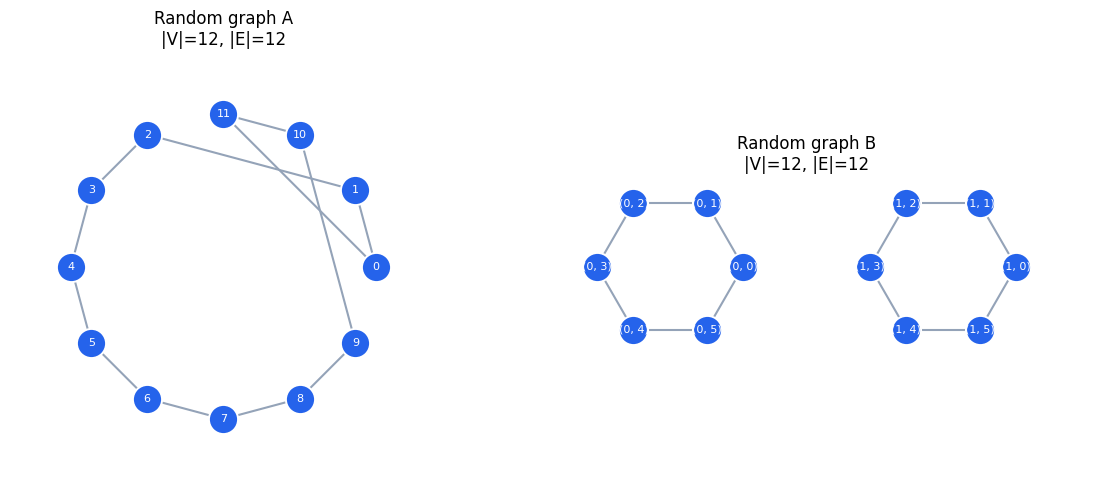

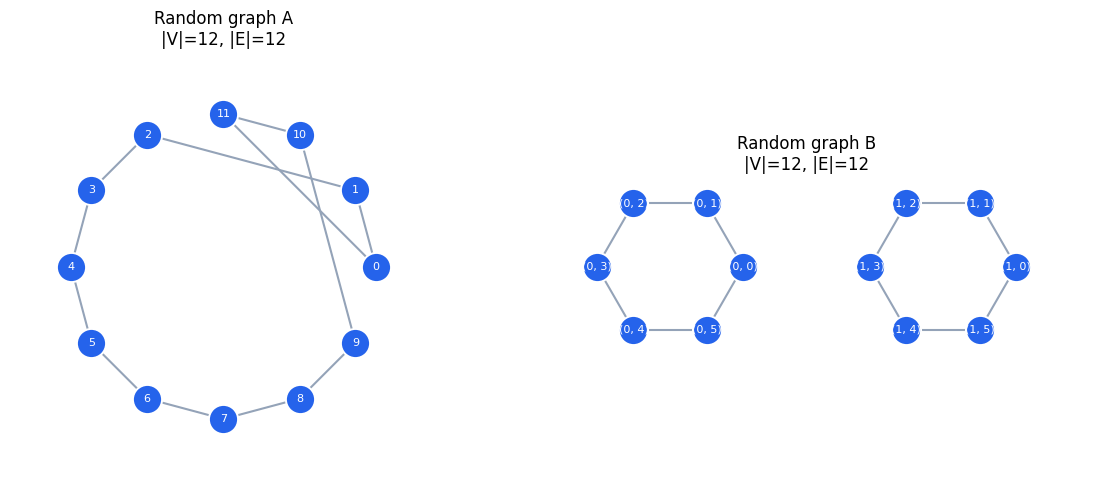

In [3]:
left, right = cycle(12), disjoint_cycles(6, 6)
for algorithm in (ColorRefinement(), TwoWL()):
    same = algorithm.refine(left).signature == algorithm.refine(right).signature
    print(f'{algorithm.name}: same signature = {same}')
print('exactly isomorphic:', is_isomorphic(left, right))
draw_pair(left, right, ('Random graph A', 'Random graph B'))

## Run the curated regression corpus

A `collision` means a non-isomorphic pair that this invariant cannot separate; it is not a bug in the runner.

In [4]:
trials = run(default_corpus(include_permutations=True), [ColorRefinement(), TwoWL()])
for trial in trials:
    print(f'{trial.case:26} {trial.algorithm:3}  {trial.verdict}')

degree-separation          1wl  separated
degree-separation          2wl  separated
rook-vs-shrikhande         1wl  collision
rook-vs-shrikhande         2wl  collision
connectedness-blindness    1wl  collision
connectedness-blindness    2wl  separated
relabelled-rook            1wl  consistent
relabelled-rook            2wl  consistent


## Search randomly for a test-breaking pair

Random regular graphs are a productive source of 1-WL collisions because all vertices begin with the same degree. The seed makes the search repeatable. The exact oracle validates any reported collision, and the edge lists let you turn it into a permanent hand-built case.

Pass `connected_only=True` to `find_collision` to skip disconnected samples and search for collisions among connected graphs only.

For Erdős–Rényi samples, use `model="erdos"` and either `average_degree=d` (which sets `p = d / (vertices - 1)`) or `probability=p`. These options are mutually exclusive.

{'algorithm': '1wl', 'seed': 7, 'samples_examined': 2, 'left_edges': [(0, 8), (0, 3), (1, 9), (1, 5), (2, 6), (2, 7), (3, 4), (4, 7), (5, 9), (6, 8)], 'right_edges': [(0, 8), (0, 2), (1, 9), (1, 7), (2, 6), (3, 5), (3, 6), (4, 8), (4, 7), (5, 9)]}


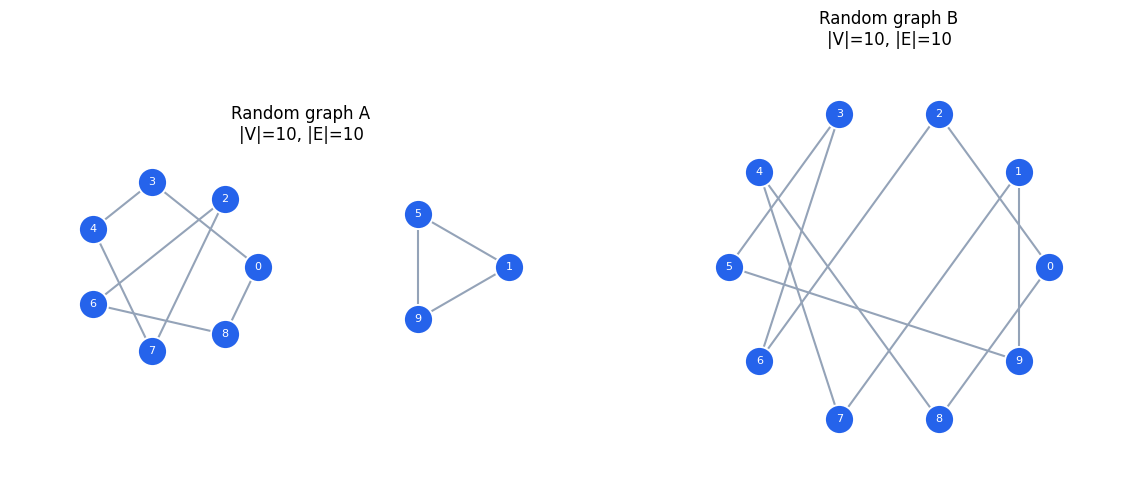

In [5]:
collision = find_collision(
    ColorRefinement(), vertices=10, degree=2, samples=40, seed=7
)
if collision is None:
    print('No collision found within this budget; try more samples or a new seed.')
else:
    print(collision.reproduce())
    draw_pair(collision.left, collision.right, ('Random graph A', 'Random graph B'))

### Search Erdős–Rényi graphs by expected average degree

Here `average_degree=4` sets the edge probability to `4 / (10 - 1)`. `connected_only=True` skips disconnected samples.

{'algorithm': 'stationary', 'seed': 7, 'samples_examined': 87, 'left_edges': [(0, 2), (0, 3), (0, 4), (1, 2), (1, 3)], 'right_edges': [(0, 2), (0, 4), (1, 3), (1, 4), (3, 4)]}


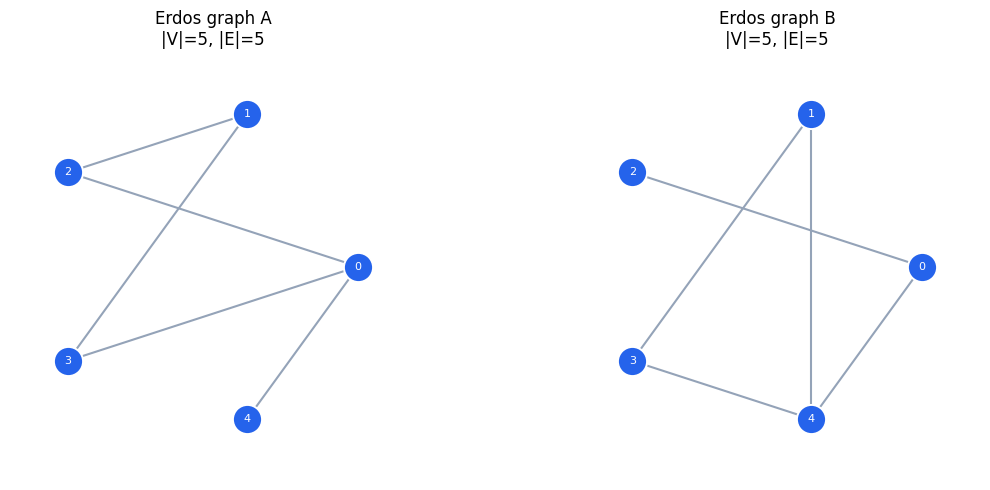

In [6]:
erdos_collision = find_collision(
    StationaryDistribution(), vertices=5, model="erdos",
    average_degree=3, samples=400, seed=7, connected_only=True
)
if erdos_collision is None:
    print("No collision found within this sample budget.")
else:
    print(erdos_collision.reproduce())
    draw_pair(erdos_collision.left, erdos_collision.right,
              ("Erdos graph A", "Erdos graph B"))

## A stronger regular-graph example

The rook and Shrikhande graphs are non-isomorphic strongly regular graphs with the same parameters. They collide under both included WL variants.

exactly isomorphic: False
1wl True
2wl True


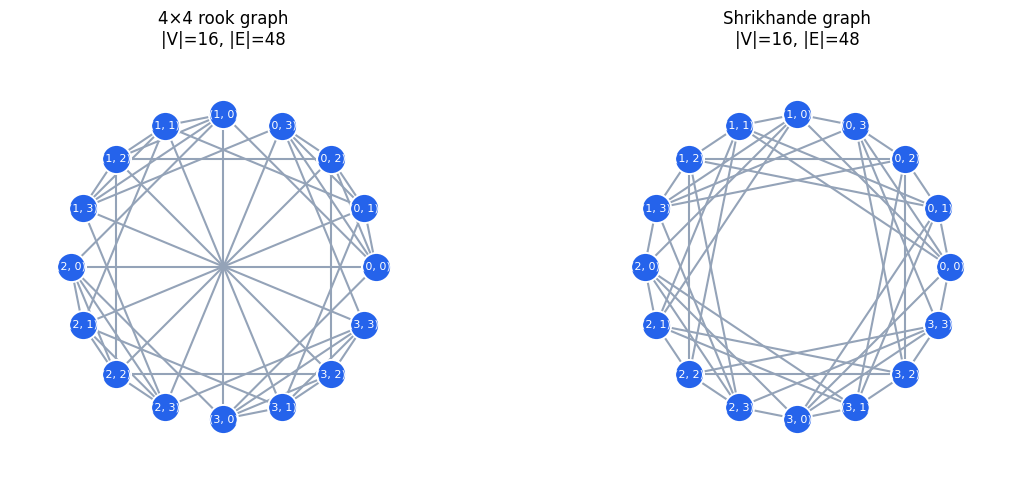

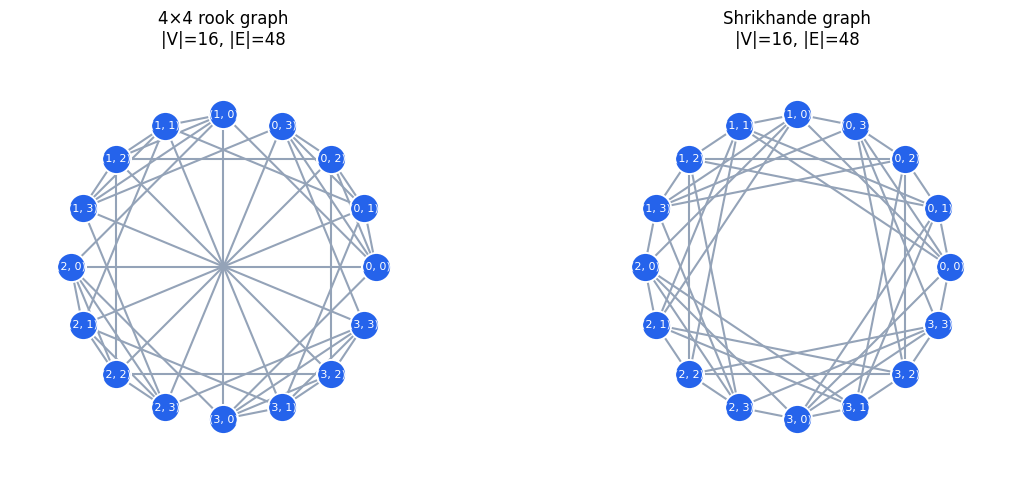

In [7]:
rook, shrikhande = rook_graph(), shrikhande_graph()
print('exactly isomorphic:', is_isomorphic(rook, shrikhande))
for algorithm in (ColorRefinement(), TwoWL()):
    print(algorithm.name, algorithm.refine(rook).signature == algorithm.refine(shrikhande).signature)
draw_pair(rook, shrikhande, ('4×4 rook graph', 'Shrikhande graph'))

## Visualize what the stationary test can and cannot tell us

For an undirected graph, the test records each vertex’s degree together with its stationary probability. Disconnected graphs are accepted too; the algorithm uses the canonical degree-weighted distribution across all components. The first pair has different degree distributions, so this test separates it. The second pair is non-isomorphic but both graphs are 6-regular, so the test gives a false positive. Run these cells to see each graph pair and compare stationary, 1-WL, and 2-WL signatures.

Path P4 (degree, probability) pairs: ((1, 0.16666666666666666), (1, 0.16666666666666666), (2, 0.3333333333333333), (2, 0.3333333333333333))
Star K1,3 (degree, probability) pairs: ((1, 0.16666666666666666), (1, 0.16666666666666666), (1, 0.16666666666666666), (3, 0.5))
same stationary signature: False
exactly isomorphic: False


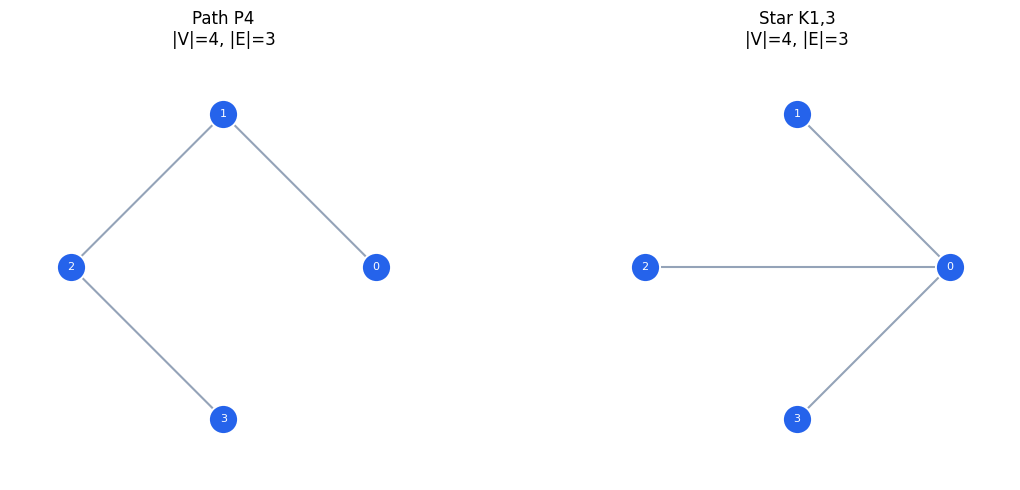

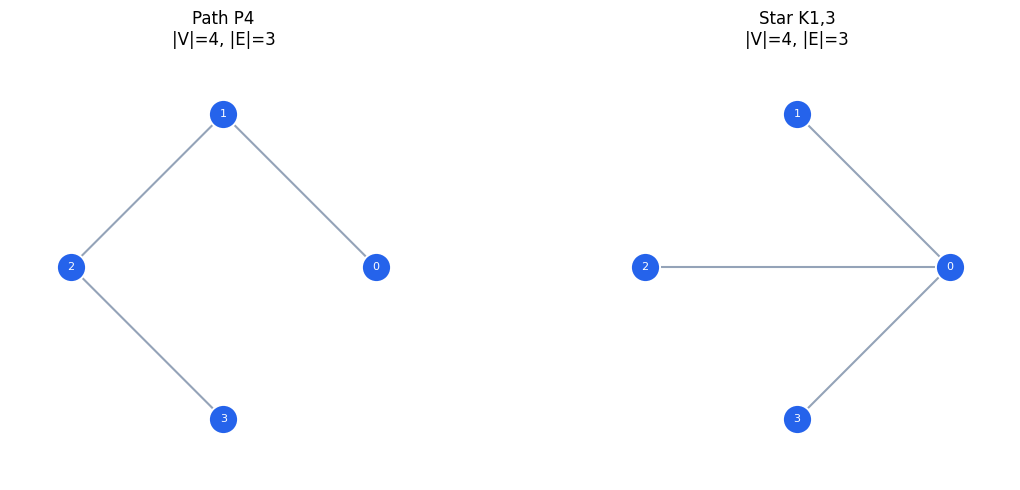

In [8]:
stationary = StationaryDistribution()

# A positive separation: path P4 and star K1,3 have different degree distributions.
path_p4 = Graph.from_edges([(0, 1), (1, 2), (2, 3)])
star_k13 = Graph.from_edges([(0, 1), (0, 2), (0, 3)])
for graph, label in ((path_p4, "Path P4"), (star_k13, "Star K1,3")):
    result = stationary.refine(graph)
    print(label, "(degree, probability) pairs:", result.signature[1])
print("same stationary signature:", stationary.refine(path_p4).signature == stationary.refine(star_k13).signature)
print("exactly isomorphic:", is_isomorphic(path_p4, star_k13))
draw_pair(path_p4, star_k13, ("Path P4", "Star K1,3"))

stationary: same signature = True
1wl: same signature = True
2wl: same signature = True
exactly isomorphic: False


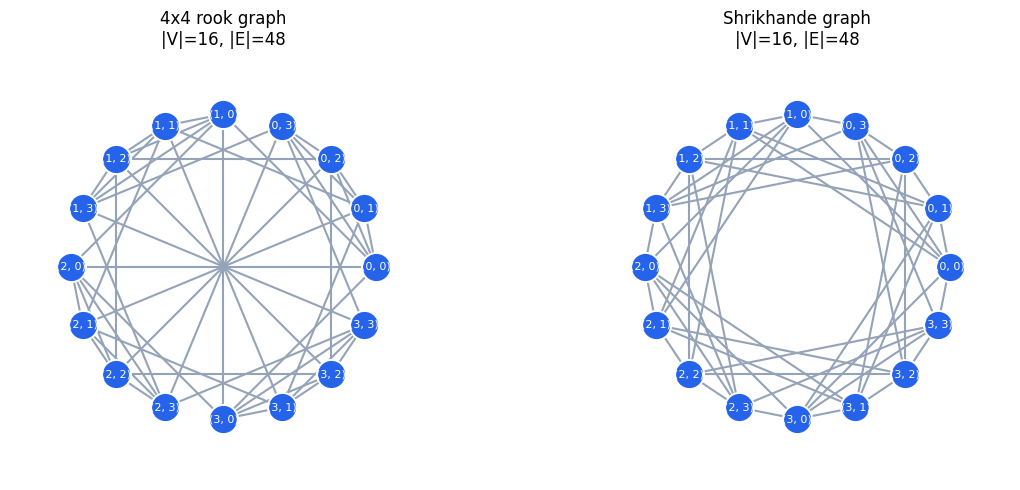

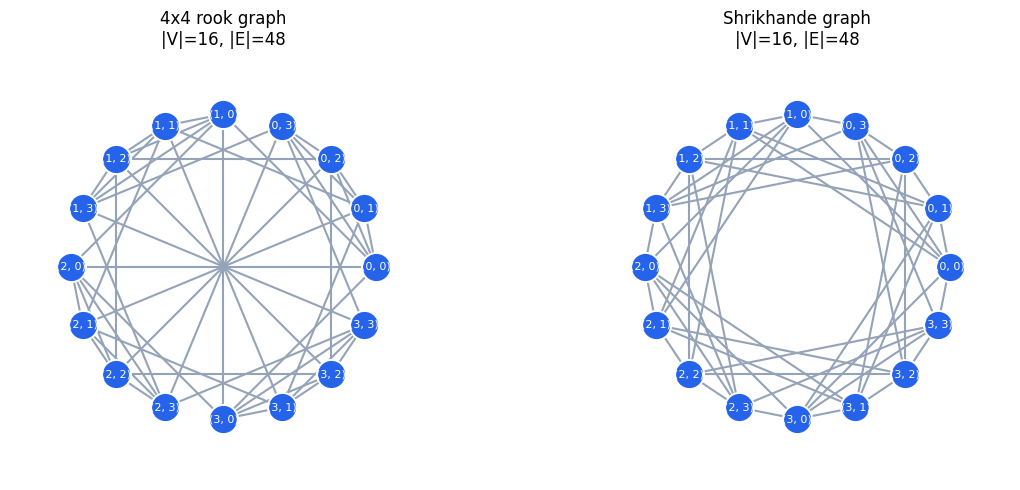

In [9]:
# A false positive: rook and Shrikhande are connected, non-isomorphic, and 6-regular.
rook, shrikhande = rook_graph(), shrikhande_graph()
for algorithm in (stationary, ColorRefinement(), TwoWL()):
    same = algorithm.refine(rook).signature == algorithm.refine(shrikhande).signature
    print(f"{algorithm.name}: same signature = {same}")
print("exactly isomorphic:", is_isomorphic(rook, shrikhande))
draw_pair(rook, shrikhande, ("4x4 rook graph", "Shrikhande graph"))

{'algorithm': 'stationary', 'seed': 7, 'samples_examined': 2, 'left_edges': [(0, 8), (0, 1), (0, 4), (0, 6), (1, 9), (1, 3), (1, 5), (2, 8), (2, 9), (2, 3), (2, 7), (3, 4), (3, 5), (4, 8), (4, 5), (5, 6), (6, 9), (6, 7), (7, 8), (7, 9)], 'right_edges': [(0, 1), (0, 4), (0, 9), (0, 7), (1, 8), (1, 2), (1, 6), (2, 8), (2, 4), (2, 7), (3, 9), (3, 4), (3, 5), (3, 7), (4, 6), (5, 8), (5, 9), (5, 7), (6, 8), (6, 9)]}


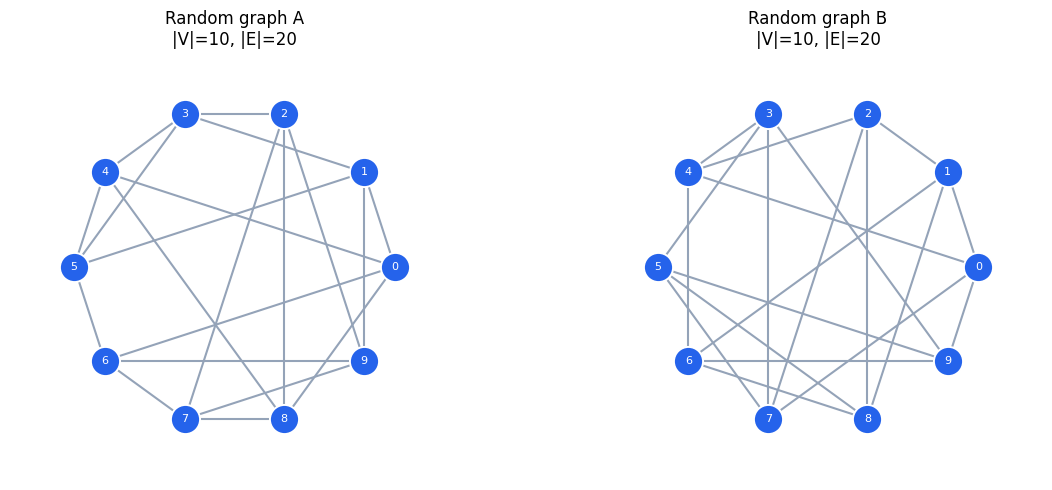

In [10]:
collision = find_collision(
    StationaryDistribution(), vertices=10, degree=4, samples=40, seed=7, connected_only=True
)
if collision is None:
    print('No collision found within this budget; try more samples or a new seed.')
else:
    print(collision.reproduce())
    draw_pair(collision.left, collision.right, ('Random graph A', 'Random graph B'))